## Phase 1  ----------------------------------------

In [1]:
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from wordcloud import WordCloud
from wordcloud import STOPWORDS
import re

In [2]:
print(plt.style.available)
plt.style.use('dark_background')
train_xml_path = "/kaggle/input/datasets/amirmohammadsharbati/dataset/Restaurants_Train_v2.xml"

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


In [3]:
tree = ET.parse(train_xml_path)
root = tree.getroot()

data = []

for sentence in root.iter("sentence"):
    text_elem = sentence.find("text")
    if text_elem is None:
        continue
    text = text_elem.text
    
    aspect_terms = sentence.find("aspectTerms")
    if aspect_terms is not None:
        for aspect in aspect_terms.findall("aspectTerm"):
            term = aspect.get("term")
            polarity = aspect.get("polarity")
            if polarity != "conflict":
                data.append({
                    "sentence": text,
                    "aspect": term,
                    "polarity": polarity
                })

df = pd.DataFrame(data)
df.head()

print("total number of datas: ", len(df))
print("\ndistro")
print(df["polarity"].value_counts())

total number of datas:  3602

distro
polarity
positive    2164
negative     805
neutral      633
Name: count, dtype: int64


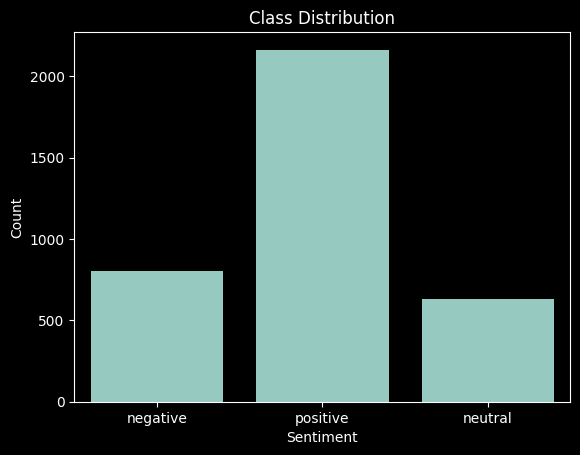

In [4]:
plt.figure()
sns.countplot(x="polarity", data=df)
plt.title("Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

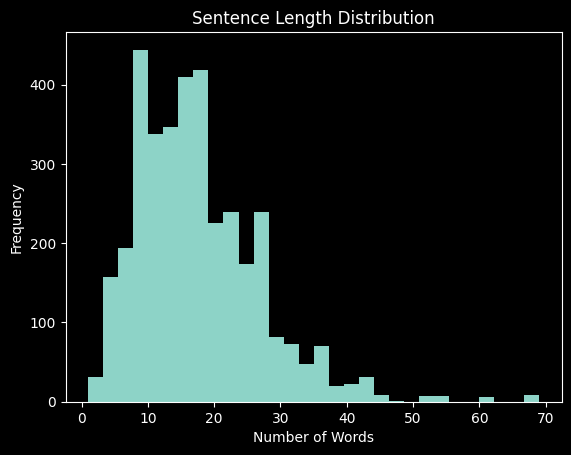

In [5]:
stopwords = set(STOPWORDS)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    words = text.split()
    words = [w for w in words if w not in stopwords]
    return " ".join(words)

df["clean_sentence"] = df["sentence"].apply(clean_text)
df["word_count"] = df["sentence"].apply(lambda x: len(x.split()))
df[["sentence", "word_count"]].head()

# Label Encoding (phase 2)
label2id = {
    "positive": 0,
    "negative": 1,
    "neutral": 2
}

df["label"] = df["polarity"].map(label2id)

plt.figure()
plt.hist(df["word_count"], bins=30)
plt.title("Sentence Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

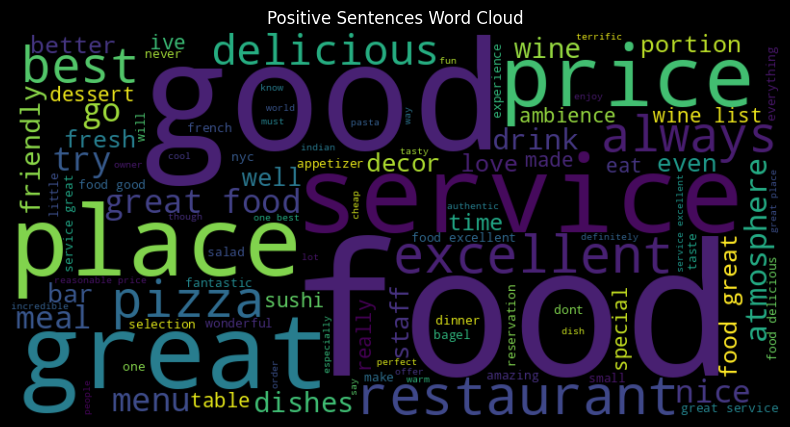

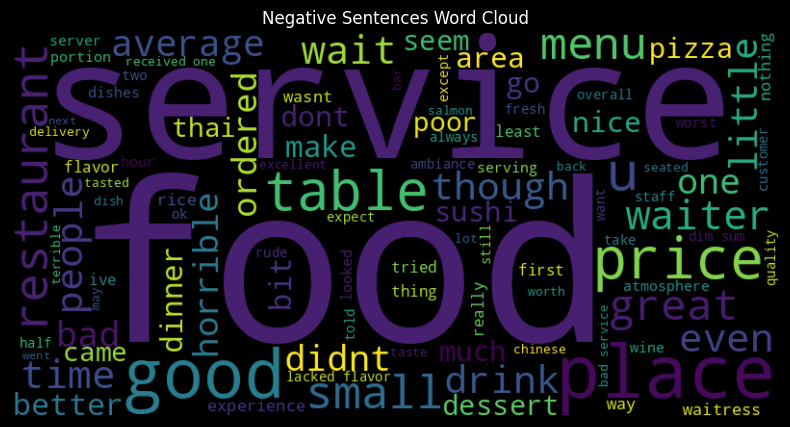

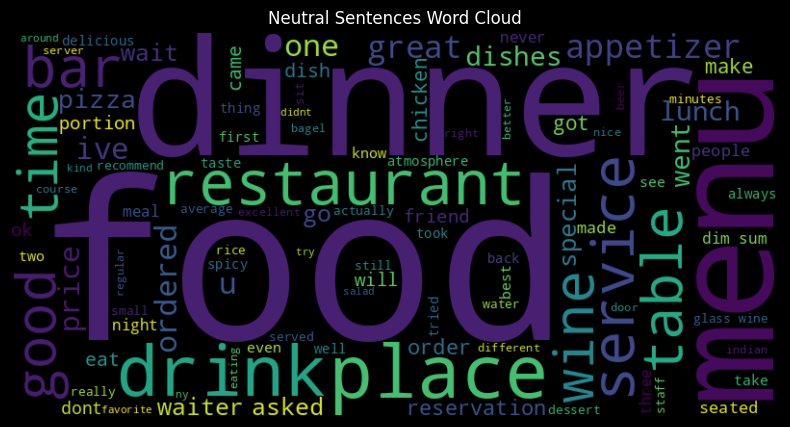

In [7]:
# Function to generate and show wordcloud
def show_wordcloud(text, title):
    wc = WordCloud(
        width=800,
        height=400,
        background_color="black",
        max_words=100,
        random_state=42
    ).generate(text)

    plt.figure(figsize=(10,5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.show()


# Generate texts
pos_text = " ".join(df[df["polarity"]=="positive"]["clean_sentence"])
neg_text = " ".join(df[df["polarity"]=="negative"]["clean_sentence"])
neu_text = " ".join(df[df["polarity"]=="neutral"]["clean_sentence"])

# Plot
show_wordcloud(pos_text, "Positive Sentences Word Cloud")
show_wordcloud(neg_text, "Negative Sentences Word Cloud")
show_wordcloud(neu_text, "Neutral Sentences Word Cloud")

---

## Phase 2 ---------------------------------

In [8]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

In [9]:
import torch
from torch.utils.data import Dataset

class ABSADataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len=128):
        self.data = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        encoding = self.tokenizer(
            row["sentence"],
            row["aspect"],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(),
            "attention_mask": encoding["attention_mask"].squeeze(),
            "labels": torch.tensor(row["label"], dtype=torch.long)
        }

In [10]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [12]:
from torch.utils.data import DataLoader

train_dataset = ABSADataset(train_df, tokenizer)
val_dataset = ABSADataset(val_df, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

In [14]:
import torch.nn as nn
from torch.optim import AdamW
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)

criterion = nn.CrossEntropyLoss()
epochs = 3

In [15]:
train_losses = []
val_losses = []
train_accs = []
val_accs = []

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch in tqdm(train_loader):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs.logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        preds = torch.argmax(outputs.logits, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_losses.append(total_loss / len(train_loader))
    train_accs.append(correct / total)

    # Validation
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(outputs.logits, labels)
            val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_losses.append(val_loss / len(val_loader))
    val_accs.append(val_correct / val_total)

    print(f"Epoch {epoch+1}")
    print(f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accs[-1]:.4f}")
    print(f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accs[-1]:.4f}")

100%|██████████| 181/181 [01:00<00:00,  3.01it/s]


Epoch 1
Train Loss: 0.7557, Train Acc: 0.6696
Val Loss: 0.5481, Val Acc: 0.7947


100%|██████████| 181/181 [01:05<00:00,  2.78it/s]


Epoch 2
Train Loss: 0.5290, Train Acc: 0.8015
Val Loss: 0.5173, Val Acc: 0.8003


100%|██████████| 181/181 [01:07<00:00,  2.70it/s]


Epoch 3
Train Loss: 0.3674, Train Acc: 0.8681
Val Loss: 0.5670, Val Acc: 0.8197


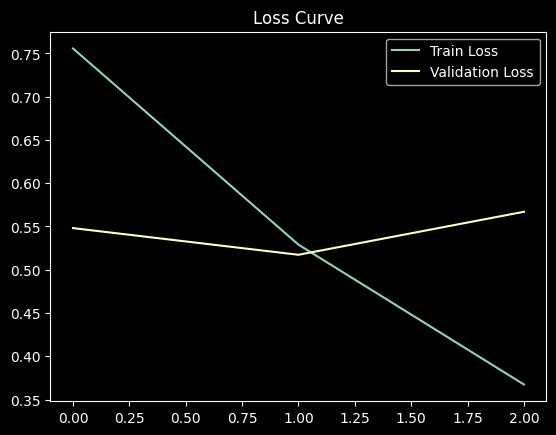

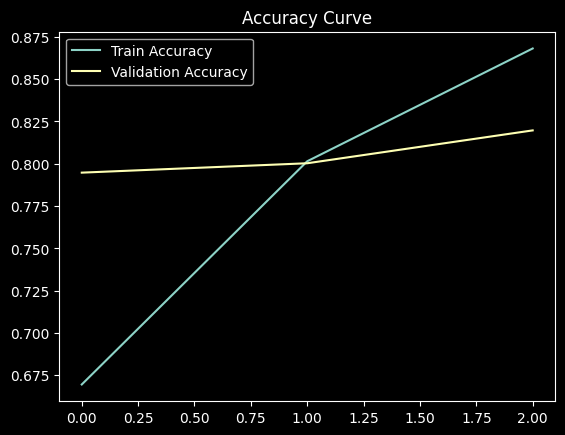

In [16]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

plt.figure()
plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

In [24]:
# Save model and tokenizer
model.save_pretrained("./final_model")
tokenizer.save_pretrained("./final_model")

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


---
## Phase 3

In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

from torch.utils.data import Dataset, DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load model and tokenizer
model_path = "./best_final_model"

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)
model.to(DEVICE)
model.eval()

print("Model loaded successfully.")

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
             

In [ ]:
def parse_semeval_xml(file_path):
    tree = ET.parse(file_path)
    root = tree.getroot()

    sentences = []
    aspects = []
    labels = []

    polarity_map = {
        "positive": 2,
        "neutral": 1,
        "negative": 0
    }

    for sentence in root.findall("sentence"):
        text = sentence.find("text").text
        
        aspect_terms = sentence.find("aspectTerms")
        if aspect_terms is None:
            continue
        
        for aspect in aspect_terms.findall("aspectTerm"):
            polarity = aspect.attrib["polarity"]
            if polarity == "conflict":
                continue  # معمولا حذف می‌شود
            
            sentences.append(text)
            aspects.append(aspect.attrib["term"])
            labels.append(polarity_map[polarity])

    return pd.DataFrame({
        "sentence": sentences,
        "aspect": aspects,
        "label": labels
    })


test_df = parse_semeval_xml("./data/Restaurants_Test_Data_phaseB.xml")
print("Test size:", len(test_df))

In [ ]:
class ABSADataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len=128):
        self.data = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        encoding = self.tokenizer(
            row["sentence"],
            row["aspect"],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(),
            "attention_mask": encoding["attention_mask"].squeeze(),
            "labels": torch.tensor(row["label"], dtype=torch.long)
        }


test_dataset = ABSADataset(test_df, tokenizer)
test_loader = DataLoader(test_dataset, batch_size=32)

              precision    recall  f1-score   support

    positive       0.84      0.97      0.90       433
    negative       0.82      0.70      0.75       161
     neutral       0.70      0.45      0.55       127

    accuracy                           0.82       721
   macro avg       0.79      0.71      0.73       721
weighted avg       0.81      0.82      0.81       721



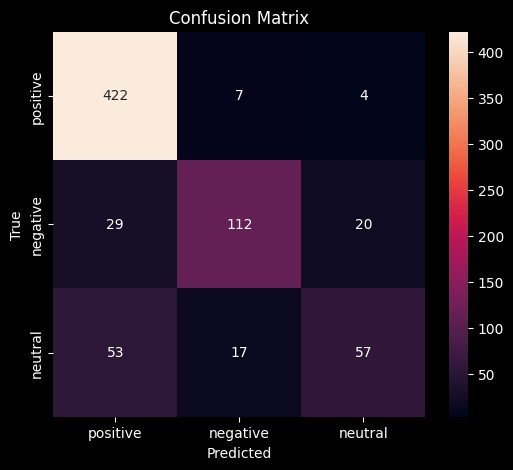

In [ ]:
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [ ]:
print("\nClassification Report:\n")

target_names = ["Negative", "Neutral", "Positive"]

print(classification_report(
    all_labels,
    all_preds,
    target_names=target_names,
    digits=4
))

macro_f1 = f1_score(all_labels, all_preds, average="macro")
print("Macro-F1:", macro_f1)


--- Error Analysis Example ---

Sentence: Ive been here so many times the waiters know my name.
Aspect: waiters
True Label: neutral
Predicted Label: positive

Possible Reason for Error:
- The sentence may contain multiple sentiment expressions.
- The model may have focused on the wrong opinion word.
- Neutral class is harder and underrepresented.


In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=target_names,
            yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Restaurants PhaseB")
plt.show()

In [ ]:
error_indices = [i for i in range(len(all_preds)) if all_preds[i] != all_labels[i]]

print("\nSample Errors:\n")

for idx in error_indices[:5]:
    print("Sentence:", test_df.iloc[idx]["sentence"])
    print("Aspect:", test_df.iloc[idx]["aspect"])
    print("True Label:", target_names[all_labels[idx]])
    print("Predicted:", target_names[all_preds[idx]])
    print("-"*60)

## تحلیل جامع فراتر از داک

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
    cohen_kappa_score,
    matthews_corrcoef
)

target_names = ["Negative", "Neutral", "Positive"]

print("\n=== Detailed Classification Report ===\n")
print(classification_report(
    all_labels,
    all_preds,
    target_names=target_names,
    digits=4
))

accuracy = accuracy_score(all_labels, all_preds)

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="macro"
)

weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="weighted"
)

kappa = cohen_kappa_score(all_labels, all_preds)
mcc = matthews_corrcoef(all_labels, all_preds)

print("\n=== Global Metrics ===")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {macro_p:.4f}")
print(f"Macro Recall: {macro_r:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"MCC: {mcc:.4f}")

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=target_names,
            yticklabels=target_names)
plt.title("Confusion Matrix (Counts)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

plt.figure(figsize=(6,5))
sns.heatmap(cm_norm, annot=True, fmt=".2f",
            xticklabels=target_names,
            yticklabels=target_names)
plt.title("Confusion Matrix (Normalized)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [ ]:
report_dict = classification_report(
    all_labels,
    all_preds,
    target_names=target_names,
    output_dict=True
)

precision_vals = [report_dict[c]["precision"] for c in target_names]
recall_vals = [report_dict[c]["recall"] for c in target_names]
f1_vals = [report_dict[c]["f1-score"] for c in target_names]

x = np.arange(len(target_names))
width = 0.25

plt.figure(figsize=(8,5))
plt.bar(x - width, precision_vals, width, label="Precision")
plt.bar(x, recall_vals, width, label="Recall")
plt.bar(x + width, f1_vals, width, label="F1-score")

plt.xticks(x, target_names)
plt.ylim(0, 1)
plt.legend()
plt.title("Per-Class Performance Comparison")
plt.show()

In [ ]:
true_counts = np.bincount(all_labels)
pred_counts = np.bincount(all_preds)

x = np.arange(len(target_names))

plt.figure(figsize=(8,5))
plt.bar(x - 0.2, true_counts, width=0.4, label="True")
plt.bar(x + 0.2, pred_counts, width=0.4, label="Predicted")

plt.xticks(x, target_names)
plt.legend()
plt.title("True vs Predicted Distribution")
plt.show()

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

all_probs = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.softmax(outputs.logits, dim=1)
        all_probs.extend(probs.cpu().numpy())

all_probs = np.array(all_probs)

y_true_bin = label_binarize(all_labels, classes=[0,1,2])

plt.figure(figsize=(7,6))
for i in range(3):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{target_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("ROC Curves (One-vs-Rest)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()